# Planning on a problem of your own

In this notebook, we go through what a new problem requires, from the map to a
path written to a file. The notebooks of `notebooks/` follow the thesis; the
scene used here does not come from the repository. It is a small warehouse
hall built in code, with four racks, aisles of 2.4 m, a cross aisle of 3 m
along the bottom wall and a charging bay cut into the east wall.

1. [The map, in metres](#1)
2. [The vehicle and the settings](#2)
3. [One start, several goals, one solve](#3)
4. [Reading the paths](#4)
5. [The figure](#5)
6. [What the settings change](#6)
7. [When a path is missing or wrong](#7)

The solves need a CUDA GPU; nothing here needs Bench-MR.

In [1]:
import sys, os, csv, tempfile, time, warnings
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

from shfm import Vehicle, from_occupancy, Planner, REFERENCE_COEFFICIENTS, SOLVER_ORDER
from shfm.postprocess import dechatter, reversals
from shfm.splice import close_start
from shfm.plotting import draw_map, draw_path, draw_footprints, draw_pose
from shfm.figures import save

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

# Where the files of this notebook go, its figures aside: a temporary folder,
# removed when the kernel stops. Set OUT_DIR to a folder of your own to keep them.
_tmp = tempfile.TemporaryDirectory(prefix="shfm-")
OUT_DIR = _tmp.name

<a id='1'></a>
## 1. The map, in metres

The planner takes a boolean array, `True` on obstacles, indexed `walls[i, j]`
with `x` along the first index and `y` along the second, upwards. One cell is
one grid unit, and `zoom` gives the number of grid units per metre: with cells
of 20 cm, `zoom = 5`. Every length the planner returns is in grid units.

The cell size is a trade-off. Obstacles snap to the cells, so a cell should be
small against the margins that matter, such as the width of an aisle less the
width of the vehicle. The solve holds `nx · ny · n_theta · 4` values, so
halving the cell multiplies the memory by four.

In [2]:
CELL = 0.2                   # metres per grid cell
ZOOM = 1 / CELL              # grid units per metre, the zoom of the planner
W, H = 30.0, 20.0            # the hall, in metres

walls = np.zeros((round(W / CELL), round(H / CELL)), dtype=bool)   # walls[x, y], y upwards

def block(x0, y0, x1, y1, value=True):
    "Fill the rectangle [x0, x1] x [y0, y1], given in metres."
    walls[round(x0 / CELL):round(x1 / CELL), round(y0 / CELL):round(y1 / CELL)] = value

block(0, 0, W, 0.4); block(0, H - 0.4, W, H); block(0, 0, 0.4, H)   # outer walls
block(28.2, 0, W, H)                                                 # a thicker east wall,
block(28.2, 8.0, 29.6, 12.0, value=False)                            # with a bay 1.4 m deep
for x in (8.0, 11.6, 15.2, 18.8):                                    # racks 1.2 m deep
    block(x, 3.4, x + 1.2, 17.0)
block(5.0, 9.0, 5.6, 9.6)                                            # a column
print("%d x %d cells of %.2f m" % (walls.shape + (CELL,)))

150 x 100 cells of 0.20 m


### From a floor plan image

A plan drawn or exported as an image works the same way once its scale is
known. The function below takes dark pixels as obstacles and brings the image
to the grid, marking a cell as an obstacle when any of its pixels is one, so
that walls thinner than a cell are kept.

`shfm.from_image` reads the maps of `data/maps/`. For other images, two of its
choices matter: only pixels of value exactly 0 are obstacles (the first
channel, for a colour image), so a dark grey wall is not read, nor every pixel
of a JPEG; and it resamples by interpolation, which can remove a wall thinner
than a cell (a 5 cm wall drawn at 5 cm per pixel disappears on 20 cm cells).

In [3]:
def occupancy_from_image(path, metres_per_pixel, cell):
    "Obstacles of a floor plan image, on a grid of `cell` metres, as walls[x, y]."
    img = plt.imread(path)                                  # first row at the top
    grey = img[..., :3].mean(axis=-1) if img.ndim == 3 else img
    if grey.dtype == np.uint8:                              # JPEG: 0 to 255
        grey = grey / 255.0
    dark = grey < 0.5
    k = round(cell / metres_per_pixel)                      # pixels per cell
    ny, nx = dark.shape[0] // k, dark.shape[1] // k
    dark = dark[dark.shape[0] - ny * k:, :nx * k]           # partial cells: top and right edges
    dark = dark.reshape(ny, k, nx, k).any(axis=(1, 3))
    return dark[::-1].T                                     # rows from the bottom, then x first

# A plan of the same hall at 5 cm per pixel, written here so that the notebook
# runs anywhere; use your own file and its scale instead.
plan = os.path.join(OUT_DIR, "hall.png")
plt.imsave(plan, np.kron(walls, np.ones((4, 4))).T[::-1], cmap="gray_r")
from_plan = occupancy_from_image(plan, metres_per_pixel=0.05, cell=CELL)
print(from_plan.shape, "identical to the array above:", np.array_equal(from_plan, walls))

(150, 100) identical to the array above: True


<a id='2'></a>
## 2. The vehicle and the settings

`Vehicle` takes its dimensions in metres: the length and the width of the
footprint, forks included, the wheelbase, and the distance from the back of
the vehicle to the rear axle. The **reference point is the centre of the rear
axle**: the poses given to the planner, and those of the path it returns, are
the poses of that point, not of the centre of the footprint. For the collision
test the footprint is covered by discs (`n_balls`, 12 by default), which reach
slightly past its sides.

`Planner` takes three groups of settings:

* **2WS or 4WS.** `delta_f_max` and `delta_r_max` are the steering limits of
  the front and rear axles, in radians, 0.5 by default. `delta_r_max=0` locks
  the rear axle: the planner then plans for a car-like vehicle, with the same
  four modes.
* **Speed coefficients.** `REFERENCE_COEFFICIENTS` ranks straight driving,
  2WS turning and 4WS manoeuvring in that order of preference, and halves the
  coefficient of reversing in navigation (`gamma_rev = 0.5`). [`docs/parameters.md`](../docs/parameters.md)
  says what each one does.
* **Transition costs.** `k1` is charged for reversing the direction of travel
  in navigation, at a cusp: raising it gives fewer cusps and longer forward
  routes. `k2` is charged for entering or leaving the manoeuvring modes, crab
  and counter-phase turns: raising it keeps the vehicle in navigation unless
  the geometry leaves no other way. They must satisfy `1 <= k1 < k2`;
  `k1 = 2`, `k2 = 3` is the setting recommended for general use. Section 6
  compares both choices on this hall.

In [4]:
vehicle = Vehicle(length=3.2, width=1.0, wheelbase=1.5, rear_axle_offset=0.45)   # metres

env = from_occupancy(walls, zoom=ZOOM, vehicle=vehicle, name="hall")
print(env)
print("vehicle: %.1f x %.1f grid units; the discs reach %.0f cm past each side"
      % (vehicle.length * ZOOM, vehicle.width * ZOOM,
         100 * (vehicle.ball_radius(ZOOM) / ZOOM - vehicle.width / 2)))

STEERING = dict(delta_f_max=0.5, delta_r_max=0.5)    # radians; delta_r_max=0 for a 2WS vehicle
planner = Planner(env, k1=2, k2=3, **STEERING, **REFERENCE_COEFFICIENTS)

Environment(name='hall', shape=(150, 100), n_theta=100, zoom=5.0, 1 unit = 0.2 m)
vehicle: 16.0 x 5.0 grid units; the discs reach 6 cm past each side


<a id='3'></a>
## 3. One start, several goals, one solve

The solve propagates a front from the start, the `seed`, over the whole map,
then extracts a path back from each goal, the `tips`. The extraction is cheap,
so one solve serves every goal from the same start.

A pose is `[x, y, heading, mode]`: `x` and `y` in grid units, the heading in
radians, counter-clockwise from the `x` axis, and the mode, an index into
`SOLVER_ORDER`. Two options leave the modes to the planner:

* `free_start_mode=True`: the vehicle may leave in any mode, at no cost.
  Leave it on: without it, the extraction can go back and forth near the
  start ([notebook 03](../notebooks/03_hamiltonian_fast_marching.ipynb),
  section 2).
* `free_goal_mode=True`: each goal is tried in every mode and the cheapest path
  is kept. Without it, the mode given with a goal only says which mode the path
  ends in, not how it arrives: a goal given in `nav_fwd` and reached in reverse
  gets a switch to `nav_fwd` on its last point, with its transition cost. The
  direction of the final approach cannot be imposed.

Check the poses before solving: a start or a goal in collision raises no error
(section 7).

In [5]:
def to_grid(x, y, heading):
    "A pose in metres and radians, as the planner takes it; the mode, 0, is left free below."
    return [x * ZOOM, y * ZOOM, heading, 0]

def in_collision(env, pose):
    "True when the vehicle at this pose overlaps an obstacle or leaves the map."
    i, j = int(np.floor(pose[0])), int(np.floor(pose[1]))
    k = int(round(pose[2] % (2 * np.pi) / (2 * np.pi / env.n_theta))) % env.n_theta
    return not (0 <= i < env.shape[0] and 0 <= j < env.shape[1]) or bool(env.walls3[i, j, k])

start = to_grid(3.0, 1.9, 0.0)
goals = {"aisle 1, facing north": to_grid(10.4, 12.0, np.pi / 2),
         "aisle 3, facing south": to_grid(17.6, 11.0, -np.pi / 2),
         "charging bay":          to_grid(28.9, 8.85, np.pi / 2)}
for name, pose in [("start", start)] + list(goals.items()):
    print("%-22s in collision: %s" % (name, in_collision(env, pose)))

t0 = time.time()
result = planner.solve(seed=start, tips=list(goals.values()),
                       free_start_mode=True, free_goal_mode=True)
print("solved in %.1f s; stopping criteria: %s"
      % (time.time() - t0, result.hfm_out["geodesic_stopping_criteria"]))

start                  in collision: False
aisle 1, facing north  in collision: False
aisle 3, facing south  in collision: False
charging bay           in collision: False
solved in 1.6 s; stopping criteria: ['AtSeed', 'AtSeed', 'AtSeed']


<a id='4'></a>
## 4. Reading the paths

`result.path(i)` is the path to goal `i`, from the start to the goal, one row
per point: `x` and `y` in grid units, the heading in radians, the mode index.
We first apply two corrections, as in the studies of the repository. `dechatter`
removes the back-and-forth steps of a fraction of a cell that the extraction
can leave. `close_start` makes the path start exactly on the requested pose,
which the extraction usually stops a cell or two short of; it takes the steering
limits of the planner, and when no connection qualifies it returns the path
unchanged, with `info["joined"]` set to `None`.

`mode_runs` lists the modes in the order they are driven. Runs of a cell or
less, such as the last three of the path to the charging bay, are steps of
the extraction rather than manoeuvres. The heading is not wrapped
along a path; it is brought into $(-\pi, \pi]$ for the export.

In [6]:
MANOEUVRE = [SOLVER_ORDER.index("man_fwd"), SOLVER_ORDER.index("man_bwd")]

def clean(path, steering=STEERING):
    "The two corrections; returns the path and what close_start did."
    path = dechatter(path)[0]
    return close_start(path, start[:3], env, vehicle.wheelbase * ZOOM,
                       steering["delta_f_max"], steering["delta_r_max"])

def length_m(path):
    "Length in metres; shfm.metrics.path_length gives the same, through Bench-MR."
    return float(np.hypot(*np.diff(path[:, :2], axis=0).T).sum()) / ZOOM

def mode_runs(path):
    "The modes in the order they are used, with the distance driven in each, in metres."
    modes = np.rint(path[:, 3]).astype(int)
    step = np.r_[np.hypot(*np.diff(path[:, :2], axis=0).T), 0.0] / ZOOM
    cuts = np.r_[0, np.flatnonzero(np.diff(modes)) + 1, len(path)]
    return [(SOLVER_ORDER[modes[a]], step[a:b].sum()) for a, b in zip(cuts[:-1], cuts[1:])]

paths = {}
for i, name in enumerate(goals):
    paths[name], info = clean(result.path(i))
    p = paths[name]
    print("%s: %.1f m, cusps %d, %.0f%% of the points manoeuvring, start %s"
          % (name, length_m(p), len(reversals(p)),
             100 * np.isin(np.rint(p[:, 3]), MANOEUVRE).mean(),
             "closed" if info["joined"] is not None else "%.2f m away" % (info["gap"] / ZOOM)))
    print("    " + " > ".join("%s %.1f m" % run for run in mode_runs(p)))

aisle 1, facing north: 16.1 m, cusps 0, 0% of the points manoeuvring, start closed
    nav_fwd 16.1 m
aisle 3, facing south: 23.9 m, cusps 1, 18% of the points manoeuvring, start closed
    nav_fwd 15.0 m > man_bwd 2.1 m > nav_bwd 6.7 m
charging bay: 35.1 m, cusps 2, 5% of the points manoeuvring, start closed
    nav_fwd 29.9 m > man_bwd 1.0 m > nav_bwd 3.9 m > nav_fwd 0.0 m > nav_bwd 0.2 m > nav_fwd 0.1 m


In [7]:
# One CSV per goal: x and y in metres, the heading in radians, the mode by name.
for i, (name, p) in enumerate(paths.items()):
    with open(os.path.join(OUT_DIR, "path_%d.csv" % i), "w", newline="") as f:
        out = csv.writer(f)
        out.writerow(["x_m", "y_m", "heading_rad", "mode"])
        for x, y, heading, mode in p:
            out.writerow(["%.3f" % (x / ZOOM), "%.3f" % (y / ZOOM),
                          "%.4f" % np.angle(np.exp(1j * heading)), SOLVER_ORDER[int(round(mode))]])

print(sorted(os.listdir(OUT_DIR)))
with open(os.path.join(OUT_DIR, "path_0.csv")) as f:
    print("".join(f.readlines()[:4]))

['hall.png', 'path_0.csv', 'path_1.csv', 'path_2.csv']
x_m,y_m,heading_rad,mode
3.000,1.900,0.0000,nav_fwd
3.040,1.900,-0.0146,nav_fwd
3.090,1.899,-0.0146,nav_fwd



<a id='5'></a>
## 5. The figure

`shfm.plotting` draws the map, the path coloured by mode, the dashed footprint
along it, and the poses: the start in grey, the goals in black, with an
arrowhead for the heading. Its axes are in grid units; for a scene laid out in
metres, the last lines of `draw` put the ticks in metres.

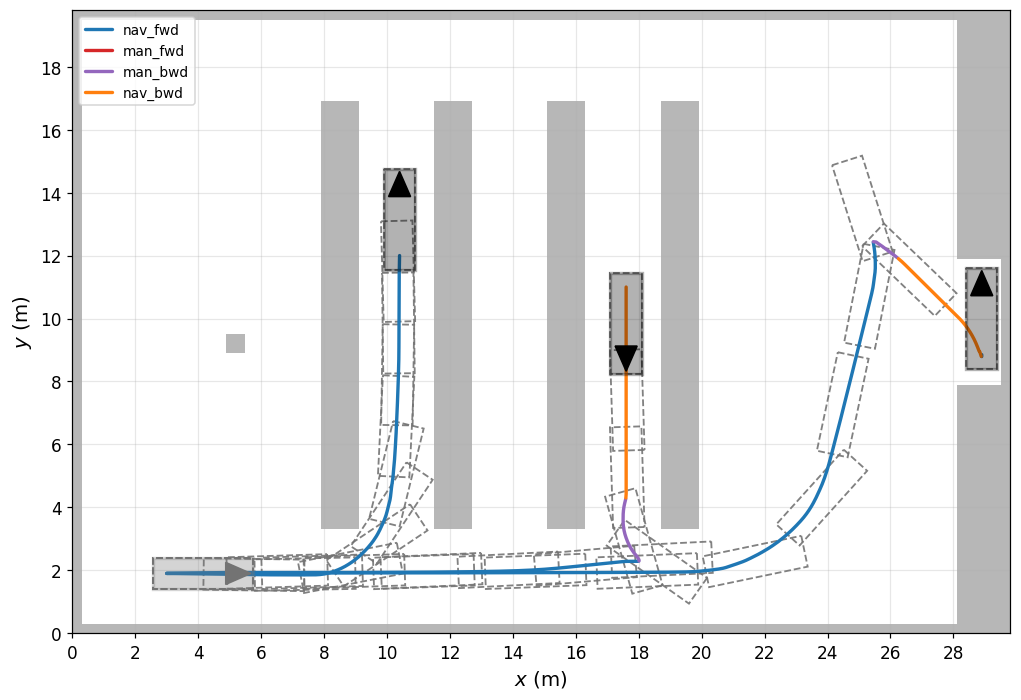

In [8]:
def draw(ax, paths, title=None, tick=2.0):
    draw_map(ax, env)
    for p in paths.values():
        draw_path(ax, p, by_state=True)
        draw_footprints(ax, p, vehicle, ZOOM, n=12, color="0.45")
    for goal in goals.values():
        draw_pose(ax, *goal[:3], vehicle, ZOOM, color="black")
    draw_pose(ax, *start[:3], vehicle, ZOOM, color="0.45")
    for axis in (ax.xaxis, ax.yaxis):                       # ticks in metres
        axis.set_major_locator(MultipleLocator(tick * ZOOM))
        axis.set_major_formatter(FuncFormatter(lambda u, _: "%g" % (u / ZOOM)))
    ax.set_xlabel("$x$ (m)"); ax.set_ylabel("$y$ (m)")
    if title:
        ax.set_title(title)
    handles = dict(zip(*ax.get_legend_handles_labels()[::-1]))   # one entry per mode
    ax.legend(handles.values(), handles.keys(), loc="upper left", fontsize=9)

fig, ax = plt.subplots(figsize=(11, 7.6))
draw(ax, paths)
save(fig, "your_own_problem"); plt.show()

<a id='6'></a>
## 6. What the settings change

We solve for the same three goals with the rear axle locked, then with the 4WS
vehicle and transition costs of 10 and 50.

                             aisle 1, facing north     aisle 3, facing south              charging bay
4WS, k1 = 2, k2 = 3      16.1 m, cusps 0, man.  0% 23.9 m, cusps 1, man. 18% 35.1 m, cusps 2, man.  5%
2WS, k1 = 2, k2 = 3      16.1 m, cusps 0, man.  0% 26.1 m, cusps 1, man.  0% 36.6 m, cusps 2, man.  0%
4WS, k1 = 10, k2 = 50    16.1 m, cusps 0, man.  0% 26.1 m, cusps 1, man.  0% 33.8 m, cusps 2, man. 19%


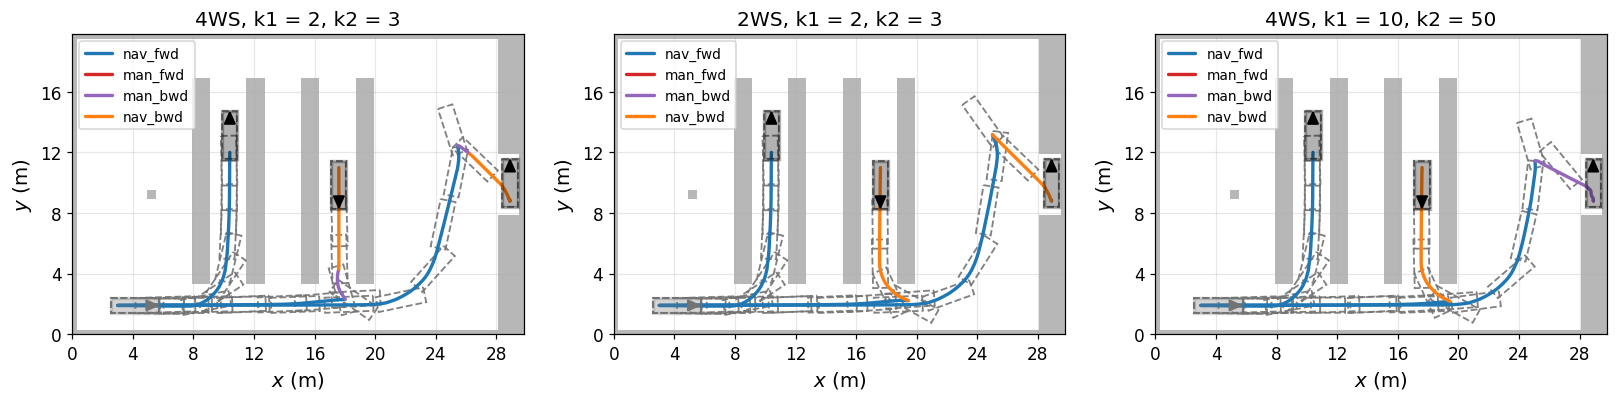

In [9]:
variants = {"4WS, k1 = 2, k2 = 3": paths}
for label, k1, k2, steering in (("2WS, k1 = 2, k2 = 3", 2, 3, dict(STEERING, delta_r_max=0.0)),
                                ("4WS, k1 = 10, k2 = 50", 10, 50, STEERING)):
    r = Planner(env, k1=k1, k2=k2, **steering, **REFERENCE_COEFFICIENTS).solve(
        seed=start, tips=list(goals.values()), free_start_mode=True, free_goal_mode=True)
    variants[label] = {name: clean(r.path(i), steering)[0] for i, name in enumerate(goals)}

print("%-24s" % "" + "".join("%26s" % name for name in goals))
for label, ps in variants.items():
    print("%-24s" % label + "".join("%26s" % ("%.1f m, cusps %d, man. %2.0f%%"
          % (length_m(p), len(reversals(p)), 100 * np.isin(np.rint(p[:, 3]), MANOEUVRE).mean()))
          for p in ps.values()))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, (label, ps) in zip(axes, variants.items()):
    draw(ax, ps, label, tick=4.0)
save(fig, "your_own_problem_settings"); plt.show()

The path to aisle 1 is the same in all three. The paths to aisle 3 differ:
with $k_2 = 3$ the 4WS vehicle turns at the foot of the aisle in a
manoeuvring mode and reverses in, while the 2WS vehicle drives past the aisle
and reverses into it on a wider curve. With $k_2 = 50$ the manoeuvre costs more
than the wider curve, and the 4WS vehicle drives as the 2WS one does.

On the charging bay the same change has the opposite effect. $k_1 = 10$ makes
reversing in navigation dearer as well, and the 4WS vehicle no longer reverses
into the bay in navigation: it enters it in a manoeuvring mode, backwards and
sideways, over
its last few metres. The transition costs are relative prices; changing them
changes which manoeuvre is the cheapest, not only how often the vehicle
manoeuvres.

<a id='7'></a>
## 7. When a path is missing or wrong

A solve raises no error when a goal cannot be reached, so that a loop over
many problems runs to the end. It emits a `RuntimeWarning` for that goal, with
its pose and the probable cause, and `result.reached(i)` is false; the path is
a single point. Below, one solve plans to the goal of aisle 1 and to the same
place facing the racks, where the vehicle does not fit. The warning is caught
and printed here; otherwise it is shown under the cell.

In [10]:
bad = to_grid(10.4, 12.0, 0.0)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    r = planner.solve(seed=start, tips=[goals["aisle 1, facing north"], bad],
                      free_start_mode=True)
for w in caught:
    print("%s: %s" % (w.category.__name__, w.message))
print("reached:", [r.reached(i) for i in range(2)])
print("points on the second path: %d" % len(r.path(1)))
i, j = int(bad[0]), int(bad[1])
print("this position is reached in another heading:", bool(np.isfinite(r.values[i, j]).any()))

reached: [True, False]
points on the second path: 1
this position is reached in another heading: True


To stop at the first such goal instead, turn the warning into an error:
`warnings.filterwarnings("error", message="goal", category=RuntimeWarning)`.

What to check, in this order:

* **A pose in collision or off the map**, the first two causes the warning
  names; `in_collision` above checks a pose before solving. A pose is that of
  the rear axle; a goal written for the centre of the footprint puts the
  vehicle `length / 2 - rear_axle_offset` too far ahead, 1.15 m here.
* **A goal cut off from the start**, the third: it is free, but enclosed or
  behind a passage the vehicle does not fit through.
  `np.isfinite(result.values)` says which configurations the front reached,
  and `np.isfinite(result.values).any(axis=(2, 3))` which cells, in any
  heading and mode.
* **The scale**: `print(env)` gives the size of a grid unit, and the vehicle
  should span `length * zoom` units. With `zoom=1` on this 20 cm grid it would
  be 3.2 units long, 64 cm, and would fit across the aisles.
* **A grid too coarse**: obstacles snap to the cells and the discs reach past
  the footprint, so a passage a little wider than the vehicle can close.
  `(~env.walls3[i, j]).sum()` counts the headings the vehicle can take at cell
  `(i, j)`: few or none along a passage means the grid has narrowed or closed
  it. Refine by scaling the array shape and `zoom` together.
* **A path that stops short of the start**. Valid paths stop `AtSeed`, and
  also `Stationnary` or `PastSeed` within a few cells of the start, which
  `close_start` closes; the warning is emitted when the stop is further than
  the vehicle length. Keep `free_start_mode=True`;
  the comparison studies also pass `geodesic_PastSeed_delay=128` to `solve`
  (notebook 05), and `close_start` joins a path that still stops short.
* **Back-and-forth steps** near the start or the goal: `dechatter`, section 4.
* **GPU memory**: [`docs/install.md`](../docs/install.md) gives 1.25 GB at the peak for a 200 x 200 grid
  with 100 headings. `from_occupancy(..., n_theta=...)` lowers the number of
  headings, at the cost of the angular resolution.

[`docs/troubleshooting.md`](../docs/troubleshooting.md) goes from a symptom to
its cause and its fix.